# Adult Mouse Brain Coronal Section

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Created: 2025-11-16
> - Modified: 2025-11-16

---

> - [Adult Mouse Brain Coronal Section (Fresh Frozen)](https://www.10xgenomics.com/datasets/adult-mouse-brain-coronal-section-fresh-frozen-1-standard)
> - Organism: Mus musculus
> - Brain Coronal Section
> - 10X Visium Spatial Protocols (V1)
> - 2023-05-26

---

# Experimental Design

> - Visium Spatial Gene Expression Reagent Kits User Guide (CG000239 Rev F)
> - Dual Index set: SI-TT-E4
> - Slide: V10L08-332
> - Area: C1
> - H&E image
> - Illumina NovaSeq
> - Space Ranger v2.1.0

| Sample | Tissue | Organ | Strain | Gender | Age | Sample status | Disease status |
| - | - | - | - | - | - | - | - |
| Donor | Coronal Section | Brain | - | Male | Adult | Fresh Frozen | Healthy |

---

In [1]:
library(tidyverse)
suppressPackageStartupMessages(library(Seurat))
suppressPackageStartupMessages(library(cowplot))

── Attaching core tidyverse packages ──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.6
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.1     ✔ tibble    3.3.0
✔ lubridate 1.9.4     ✔ tidyr     1.3.2
✔ purrr     1.2.0     
── Conflicts ────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


# 1. Data Import

In [2]:
data_dir <- "~/data1/single_cell_dataset/dataset_10xGenomics/Mm_Brain_VisiumV1_FF"

In [3]:
dir.create(file.path(data_dir, "result"), 
           recursive = TRUE, showWarnings = FALSE)
dir.create(file.path(data_dir, "visualization"), 
           recursive = TRUE, showWarnings = FALSE)

In [4]:
strna <- file.path(data_dir, "outs") |> 
    Load10X_Spatial(filename = "filtered_feature_bc_matrix.h5")

In [5]:
strna

An object of class Seurat 
32285 features across 2702 samples within 1 assay 
Active assay: Spatial (32285 features, 0 variable features)
 1 layer present: counts
 1 spatial field of view present: slice1

# 2. Quality Control

## 1). Calculate Metrics

In [6]:
# Mitochondrial genes
mt <- "(?i)^MT-"
strna <- PercentageFeatureSet(
    strna, pattern = mt, col.name = "percent.mt")

In [7]:
# Ribosomal genes
rp <- "(?i)^(MRP|RP[LS])"
strna <- PercentageFeatureSet(
    strna, pattern = rp, col.name = "percent.rp")

In [8]:
# Hemoglobin genes
hb <- "^(Hb[ab]-|Hbq1[ab])"
strna <- PercentageFeatureSet(
    strna, pattern = hb, col.name = "percent.hb")

In [9]:
strna@meta.data |> head()

,orig.ident,nCount_Spatial,nFeature_Spatial,percent.mt,percent.rp,percent.hb
,<chr>,<dbl>,<int>,<dbl>,<dbl>,<dbl>
AAACAAGTATCTCCCA-1,SeuratProject,20935,5230,19.27872,3.878672,0.1003105
AAACAATCTACTAGCA-1,SeuratProject,14789,3646,23.11853,6.917303,0.2434242
AAACACCAATAACTGC-1,SeuratProject,34646,6272,14.62795,10.644807,1.2064885
AAACAGAGCGACTCCT-1,SeuratProject,16833,4506,20.10931,5.916949,1.0930910
AAACCGGGTAGGTACC-1,SeuratProject,33684,5971,20.60622,7.888018,0.2790642
AAACCGTTCGTCCAGG-1,SeuratProject,32563,6097,16.49418,7.938458,2.4383503


## 2). Visualizate Metrics

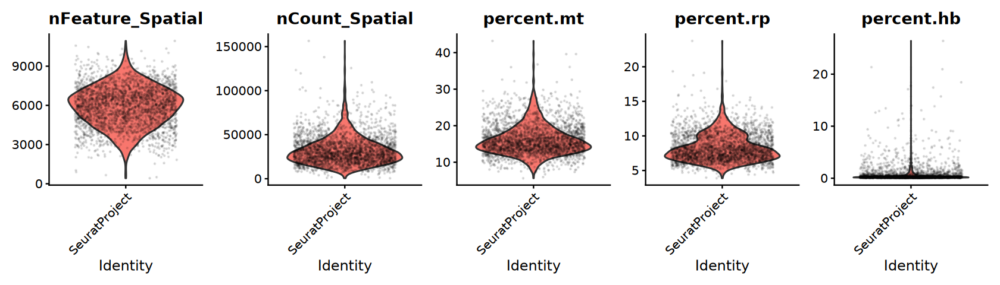

In [10]:
options(repr.plot.width = 14, repr.plot.height = 4)
VlnPlot(strna, layer = "counts", group.by = "orig.ident",
        features = c("nFeature_Spatial", "nCount_Spatial", "percent.mt", 
                     "percent.rp", "percent.hb"), 
        pt.size = 0.1, alpha = 0.1, ncol = 5) & NoLegend()

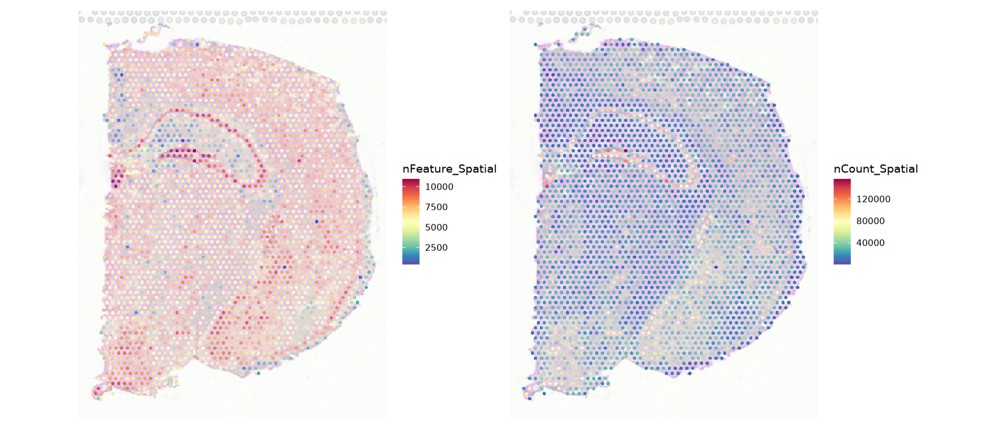

In [11]:
options(repr.plot.width = 14, repr.plot.height = 6)
SpatialFeaturePlot(strna, features = c("nFeature_Spatial", "nCount_Spatial"),
                   image.alpha = 0.5, pt.size.factor = 1.6) & 
    theme(legend.position = "right")

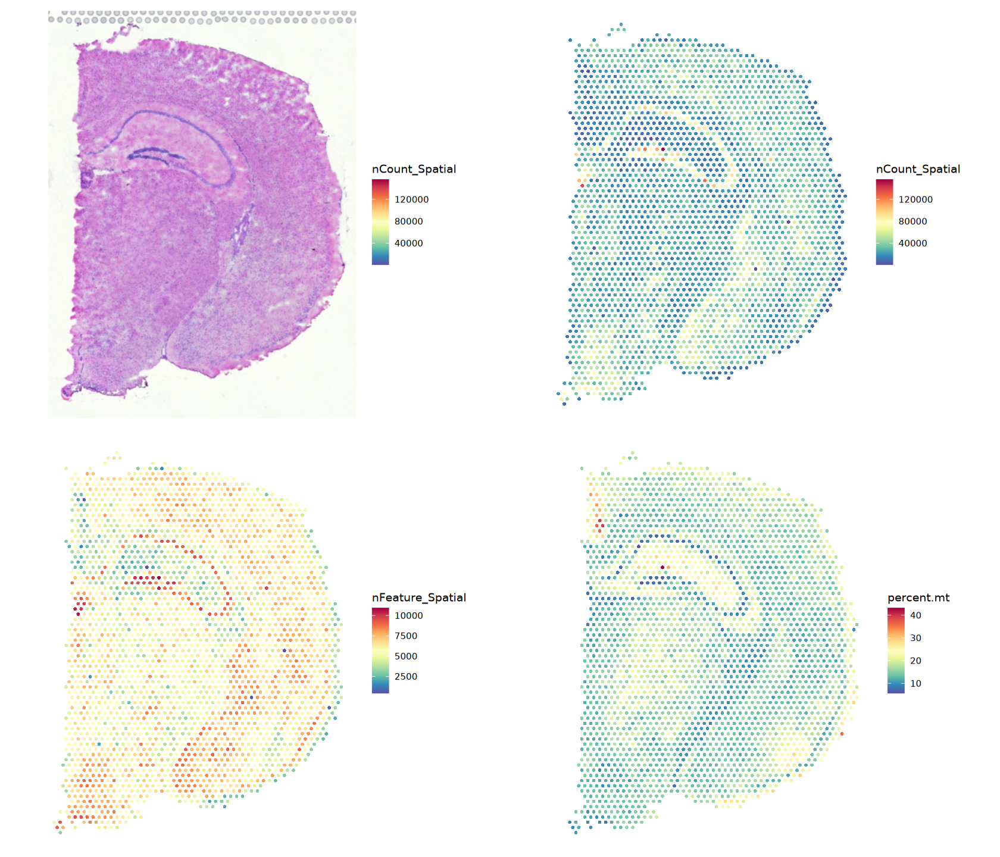

In [12]:
p1 <- SpatialFeaturePlot(
    strna, features = "nCount_Spatial", 
    image.alpha = 1, pt.size.factor = 0) + 
    theme(legend.position = "right")
p2 <- SpatialFeaturePlot(
    strna, features = c("nCount_Spatial", "nFeature_Spatial", "percent.mt"),
    image.alpha = 0, pt.size.factor = 1.6, combine = FALSE) |>
    lapply(function(p) {
        p + theme(legend.position = "right")
    })

options(repr.plot.width = 14, repr.plot.height = 12)
plot_grid(plotlist = c(p1, p2), ncol = 2)

# 3. Normalization

## a). LogNormalize

In [13]:
strna <- NormalizeData(
    strna, assay = "Spatial", verbose = FALSE) |>
    FindVariableFeatures(nfeatures = 2000, verbose = FALSE) |>
    ScaleData(verbose = FALSE)
strna

An object of class Seurat 
32285 features across 2702 samples within 1 assay 
Active assay: Spatial (32285 features, 2000 variable features)
 3 layers present: counts, data, scale.data
 1 spatial field of view present: slice1

## b). SCTransform

In [14]:
strna <- SCTransform(
    strna, assay = "Spatial", verbose = FALSE)
strna

An object of class Seurat 
51053 features across 2702 samples within 2 assays 
Active assay: SCT (18768 features, 3000 variable features)
 3 layers present: counts, data, scale.data
 1 other assay present: Spatial
 1 spatial field of view present: slice1

In [15]:
DefaultAssay(strna) <- "Spatial"

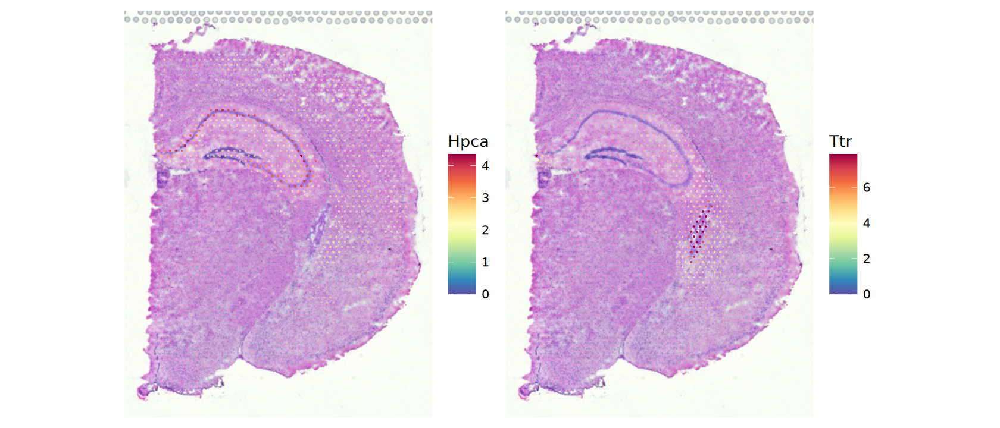

In [16]:
# Hippocampus: Hpca
# Choroid plexus: Ttr
options(repr.plot.width = 14, repr.plot.height = 6)
SpatialFeaturePlot(strna, features = c("Hpca", "Ttr"), 
                   pt.size.factor = 1, alpha = c(0.1, 1)) & 
    theme(legend.position = "right",
          legend.text = element_text(size = 12),
          legend.title = element_text(size = 16), 
          legend.key.size = unit(1, "cm"))

## c). Spatially-aware normalization

In [ ]:
seurat_obj <- SpaNorm(seurat_obj, sample.p = 0.1, df.tps = 2, backend = "cpu", verbose = FALSE)
seurat_obj

# 5. Linear Dimensionality Reduction

In [17]:
strna <- RunPCA(strna, npcs = 50, verbose = FALSE)

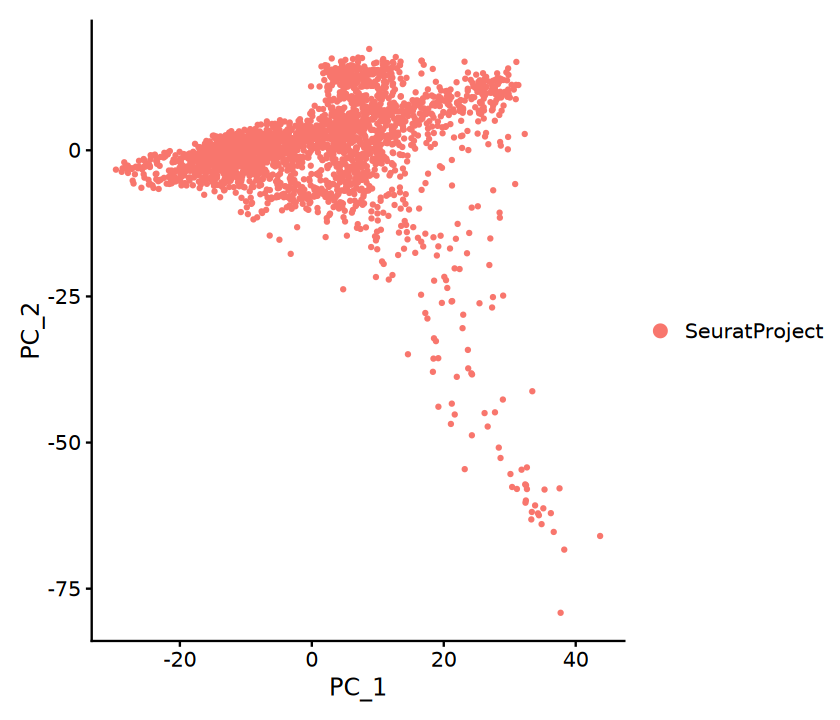

In [18]:
options(repr.plot.width = 7, repr.plot.height = 6)
DimPlot(strna, reduction = "pca")

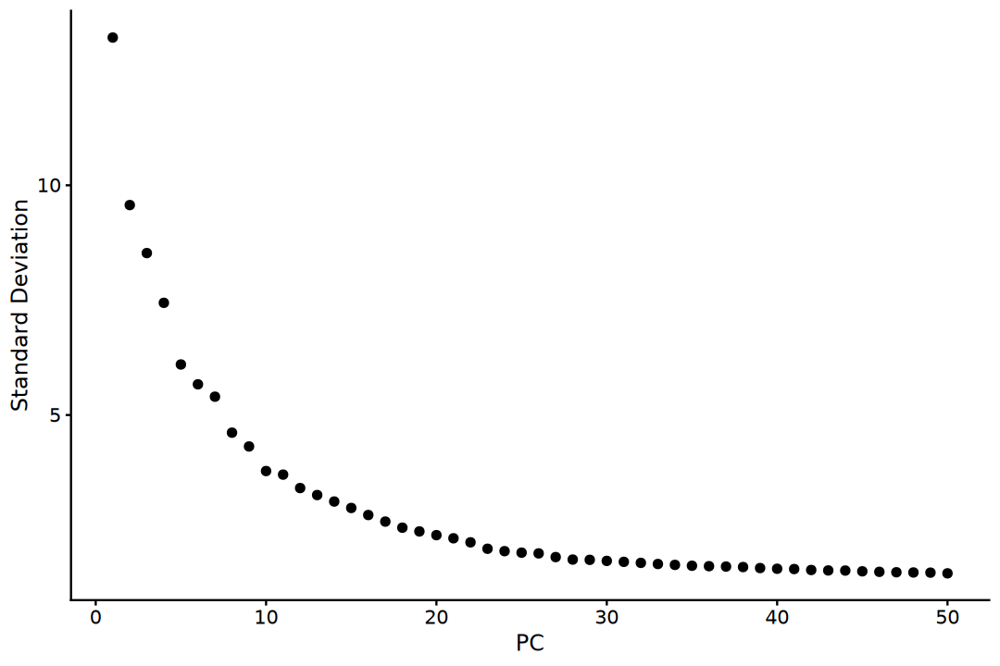

In [19]:
options(repr.plot.width = 9, repr.plot.height = 6)
ElbowPlot(strna, ndims = 50)

In [20]:
# Estimating PCA dimensionality
pca_var <- strna@reductions$pca@stdev^2
pca_con <- pca_var / sum(pca_var)
nPCs <- which(cumsum(pca_con) > 0.9 & pca_con < 0.05)[1]
print(nPCs)

[1] 25


In [21]:
nPCs <- 30

# 7. Neighborhood Graph Construction

In [22]:
strna <- FindNeighbors(
    strna, reduction = "pca", k.param = 20,
    dims = 1:nPCs, verbose = FALSE)

An object of class Seurat 
51053 features across 2702 samples within 2 assays 
Active assay: Spatial (32285 features, 2000 variable features)
 3 layers present: counts, data, scale.data
 1 other assay present: SCT
 1 dimensional reduction calculated: pca
 1 spatial field of view present: slice1

# 8. Non-linear Dimensionality Reduction

In [23]:
strna <- RunUMAP(
    strna, dims = 1:nPCs, reduction = "pca", 
    verbose = FALSE)

Warning message:
“The default method for RunUMAP has changed from calling Python UMAP via reticulate to the R-native UWOT using the cosine metric
To use Python UMAP via reticulate, set umap.method to 'umap-learn' and metric to 'correlation'
This message will be shown once per session”


In [24]:
strna <- RunTSNE(
    strna, dims = 1:nPCs, reduction = "pca", 
    verbose = FALSE)

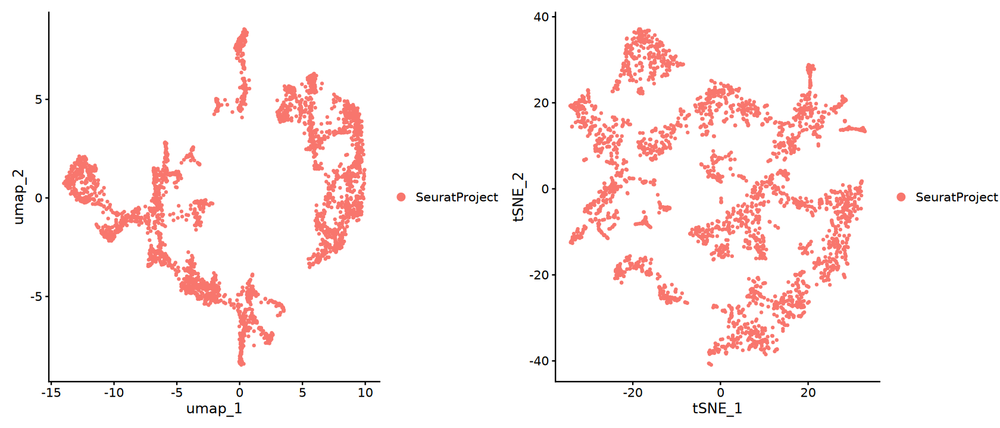

In [26]:
p1 <- DimPlot(strna, reduction = "umap")
p2 <- DimPlot(strna, reduction = "tsne")

options(repr.plot.width = 14, repr.plot.height = 6)
plot_grid(p1, p2, ncol = 2)

# 9. Clustering

In [30]:
strna <- FindClusters(
    strna, resolution = 0.5, verbose = FALSE)

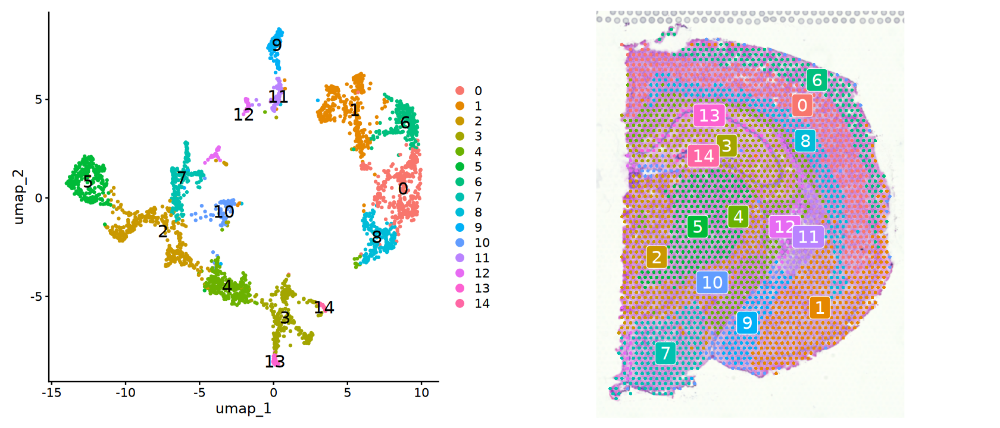

In [34]:
p1 <- DimPlot(
    strna, reduction = "umap", label = TRUE, 
    label.size = 6, repel = FALSE)
p2 <- SpatialDimPlot(
    strna, label = TRUE, label.size = 6) &
    NoLegend()

options(repr.plot.width = 14, repr.plot.height = 6)
plot_grid(p1, p2, ncol = 2)

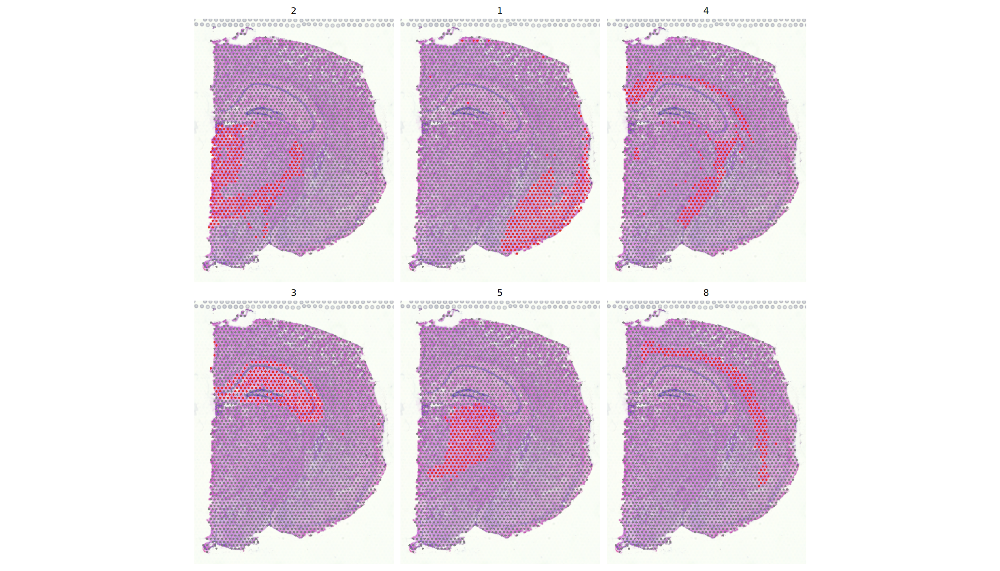

In [37]:
options(repr.plot.width = 21, repr.plot.height = 12)
SpatialDimPlot(
    strna, cells.highlight = CellsByIdentities(
        strna, idents = c(2, 1, 4, 3, 5, 8)),
    facet.highlight = TRUE, ncol = 3)

In [38]:
strna

An object of class Seurat 
51053 features across 2702 samples within 2 assays 
Active assay: Spatial (32285 features, 2000 variable features)
 3 layers present: counts, data, scale.data
 1 other assay present: SCT
 3 dimensional reductions calculated: pca, umap, tsne
 1 spatial field of view present: slice1

# 10. Cluster Biomarkers

## a). Method 1
differential expression based on pre-annotated anatomical regions within the tissue

In [39]:
sc.markers <- FindAllMarkers(
    strna, logfc.threshold = log2(1.2), min.pct = 0.25, 
    only.pos = TRUE, verbose = FALSE)

In [40]:
sc.markers.filt <- sc.markers |> 
    filter(p_val_adj < 0.01, 
           avg_log2FC > log2(1.2), 
           pct.1 - pct.2 > 0.2)

In [41]:
sc.markers.filt |> 
    group_by(cluster) |> 
    summarise(length(gene)) |>
    t()

cluster,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
length(gene),301,102,111,20,307,261,370,744,568,536,400,260,1432,816,730


In [47]:
top10 <- sc.markers.filt |> group_by(cluster) |> 
    top_n(10, wt = avg_log2FC)

top3 <- sc.markers.filt |> group_by(cluster) |> 
    top_n(3, wt = avg_log2FC)

## b). Method 2
search for features exhibiting spatial patterning in the absence of pre-annotation.

In [48]:
strna <- FindSpatiallyVariableFeatures(
    strna, features = VariableFeatures(strna),
    selection.method = "moransi")

Computing Moran's I

Warning message in dist(x = pos):
“NAs introduced by coercion”


In [50]:
top.features <- SpatiallyVariableFeatures(strna, method = "moransi")

In [53]:
head(top.features)

[1] "Nrgn"    "Slc17a7" "Camk2n1" "Sparc"   "Tcf7l2"  "Agt"

## Visualization

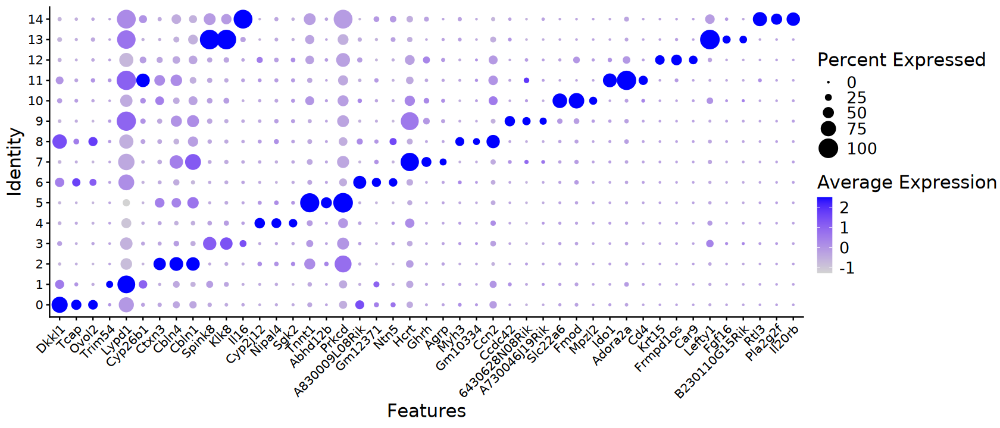

In [54]:
options(repr.plot.width = 14, repr.plot.height = 6)
DotPlot(strna, features = unique(top3$gene), dot.scale = 8) + 
    RotatedAxis() + 
    theme(axis.title = element_text(size = 18),
          axis.text = element_text(size = 12),
          legend.title = element_text(size = 18), 
          legend.text = element_text(size = 16))

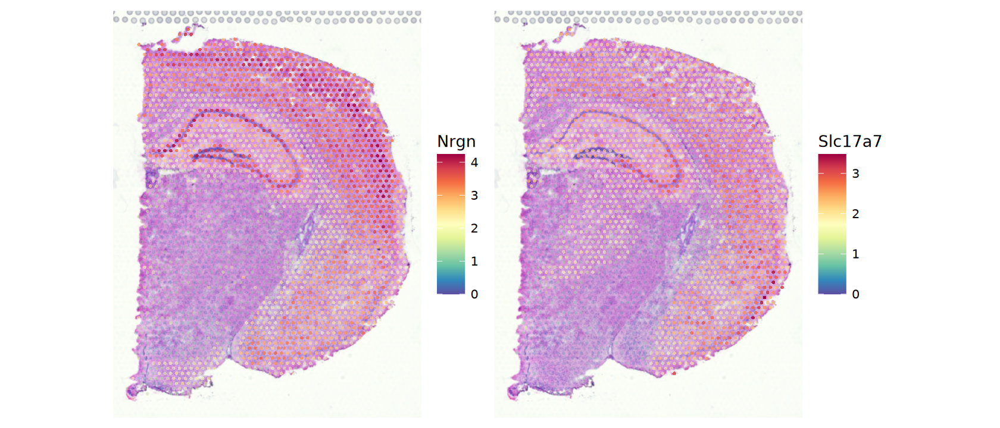

In [57]:
options(repr.plot.width = 14, repr.plot.height = 6)
SpatialFeaturePlot(strna, features = top.features |> head(2), 
                   alpha = c(0.1, 1), ncol = 2) & 
    theme(legend.position = "right",
          legend.text = element_text(size = 12),
          legend.title = element_text(size = 16), 
          legend.key.size = unit(1, "cm"))

# 11. Cell-type Annotation